## All you need is love… And a pet!

<img src="img/dataset-cover.jpg" width="920">

Here we are going to build a classifier to predict whether an animal from an animal shelter will be adopted or not (aac_intakes_outcomes.csv, available at: https://www.kaggle.com/aaronschlegel/austin-animal-center-shelter-intakes-and-outcomes/version/1#aac_intakes_outcomes.csv). You will be working with the following features:

1. *animal_type:* Type of animal. May be one of 'cat', 'dog', 'bird', etc.
2. *intake_year:* Year of intake
3. *intake_condition:* The intake condition of the animal. Can be one of 'normal', 'injured', 'sick', etc.
4. *intake_number:* The intake number denoting the number of occurrences the animal has been brought into the shelter. Values higher than 1 indicate the animal has been taken into the shelter on more than one occasion.
5. *intake_type:* The type of intake, for example, 'stray', 'owner surrender', etc.
6. *sex_upon_intake:* The gender of the animal and if it has been spayed or neutered at the time of intake
7. *age_upon\_intake_(years):* The age of the animal upon intake represented in years
8. *time_in_shelter_days:* Numeric value denoting the number of days the animal remained at the shelter from intake to outcome.
9. *sex_upon_outcome:* The gender of the animal and if it has been spayed or neutered at time of outcome
10. *age_upon\_outcome_(years):* The age of the animal upon outcome represented in years
11. *outcome_type:* The outcome type. Can be one of ‘adopted’, ‘transferred’, etc.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy as sp
from itertools import combinations 
import ast
from sklearn.linear_model import LogisticRegression
import seaborn as sn
%matplotlib inline

data_folder = './data/'

### A) Load the dataset and convert categorical features to a suitable numerical representation (use dummy-variable encoding). 
- Split the data into a training set (80%) and a test set (20%). Pair each feature vector with the corresponding label, i.e., whether the outcome_type is adoption or not. 
- Standardize the values of each feature in the data to have mean 0 and variance 1.

The use of external libraries is not permitted in part A, except for numpy and pandas. 
You can drop entries with missing values.

In [2]:
columns = ['animal_type', 'intake_year', 'intake_condition', 'intake_number', 'intake_type', 'sex_upon_intake', \
          'age_upon_intake_(years)', 'time_in_shelter_days', 'sex_upon_outcome', 'age_upon_outcome_(years)', \
          'outcome_type']
original_data = pd.read_csv(data_folder+'aac_intakes_outcomes.csv', usecols=columns)

In [5]:
original_data.head()

,outcome_type,sex_upon_outcome,age_upon_outcome_(years),animal_type,intake_condition,intake_type,sex_upon_intake,age_upon_intake_(years),intake_year,intake_number,time_in_shelter_days
0,Return to Owner,Neutered Male,10.0,Dog,Normal,Stray,Neutered Male,10.0,2017,1.0,0.588194
1,Return to Owner,Neutered Male,7.0,Dog,Normal,Public Assist,Neutered Male,7.0,2014,2.0,1.259722
2,Return to Owner,Neutered Male,6.0,Dog,Normal,Public Assist,Neutered Male,6.0,2014,3.0,1.113889
3,Transfer,Neutered Male,10.0,Dog,Normal,Owner Surrender,Neutered Male,10.0,2014,1.0,4.970139
4,Return to Owner,Neutered Male,16.0,Dog,Injured,Public Assist,Neutered Male,16.0,2013,1.0,0.119444


In [28]:
X = original_data.drop(columns="outcome_type")
y = original_data["outcome_type"]

# Convert categorical features into numbers
X = pd.get_dummies(X, dtype=int)
y = (y == "Adoption").astype(int)
print(f"{y.mean()*100:.2f}% of animals were adopted")

indices = np.random.permutation(len(X))
split = int(0.8*len(X))

train_idx = indices[:split]
test_idx = indices[split:]

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print(f"Size of training set: {len(X_train)}")
print(f"Size of test set: {len(X_test)}")

42.17% of animals were adopted
Size of training set: 63737
Size of test set: 15935


In [29]:
mean = X_train.mean()
std = X_train.std()

X_train = (X_train - mean)/std
X_test = (X_test - mean)/ std

### B) Train a logistic regression classifier on your training set. Logistic regression returns probabilities as predictions, so in order to arrive at a binary prediction, you need to put a threshold on the predicted probabilities. 
- For the decision threshold of 0.5, present the performance of your classifier on the test set by displaying the confusion matrix. Based on the confusion matrix, manually calculate accuracy, precision, recall, and F1-score with respect to the positive and the negative class. 

In [31]:
logistic = LogisticRegression(solver="lbfgs")
logistic.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [41]:
y_proba = logistic.predict_proba(X_test)
y_pred = (y_proba[:,1] >= 0.5).astype(int)

In [43]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

[[7607 1600]
 [1211 5517]]


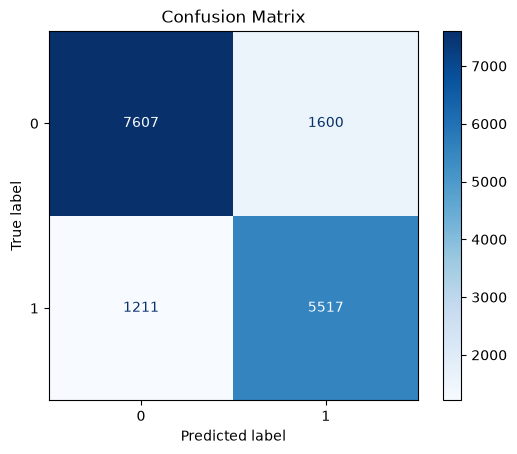

In [47]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    cmap='Blues'
)

plt.title('Confusion Matrix')
plt.show()

In [62]:
TN, FP, FN, TP = cm.ravel()
N = len(y_test)

accuracy = (TP+TN) / N
precision = TP / (TP+FP)
recall = TP / (TP+FN)
f1_score = (2*precision*recall)/(precision+recall)

print(f"Accuracy:           {accuracy:.3f}")
print(f"Positive precision: {precision:.3f}")
print(f"Positive recall:    {recall:.3f}")
print(f"Positive F1-score:  {f1_score:.3f}")

Accuracy:           0.824
Positive precision: 0.775
Positive recall:    0.820
Positive F1-score:  0.797


In [63]:
recall_pos = TP / (TP + FN)
recall_neg = TN / (TN + FP)
precision_pos = TP / (TP + FP)
precision_neg = TN / (TN + FN)
f1_pos = 2 * precision_pos * recall_pos / (precision_pos + recall_pos)
f1_neg = 2 * precision_neg * recall_neg / (precision_neg + recall_neg)

print(f"Positive precision: {precision_pos:.3f}")
print(f"Negative precision: {precision_neg:.3f}")
print(f"Positive recall:    {recall_pos:.3f}")
print(f"Negative recall:    {recall_neg:.3f}")
print(f"Positive F1-score:  {f1_pos:.3f}")
print(f"Negative F1-score:  {f1_neg:.3f}")

Positive precision: 0.775
Negative precision: 0.863
Positive recall:    0.820
Negative recall:    0.826
Positive F1-score:  0.797
Negative F1-score:  0.844


### C) Vary the value of the threshold in the range from 0 to 1 and visualize the value of accuracy, precision, recall, and F1-score (with respect to both classes) as a function of the threshold.

In [65]:
thresholds = np.linspace(0, 1, 101)

accuracy = []
recall_pos, recall_neg = [], []
precision_pos, precision_neg = [], []
f1_pos, f1_neg = [], []

N = len(y_test)

def safe_divide(a, b):
    return a / b if b != 0 else np.nan

for threshold in thresholds:
    y_pred = (y_proba[:, 1] >= threshold).astype(int)

    TN, FP, FN, TP = confusion_matrix(y_test, y_pred).ravel()

    accuracy.append((TP + TN) / N)

    recall_pos.append(safe_divide(TP, TP + FN))
    recall_neg.append(safe_divide(TN, TN + FP))

    precision_pos.append(safe_divide(TP, TP + FP))
    precision_neg.append(safe_divide(TN, TN + FN))

    f1_pos.append(2 * precision_pos[-1] * recall_pos[-1] /
                  (precision_pos[-1] + recall_pos[-1]))

    f1_neg.append(2 * precision_neg[-1] * recall_neg[-1] /
                  (precision_neg[-1] + recall_neg[-1]))

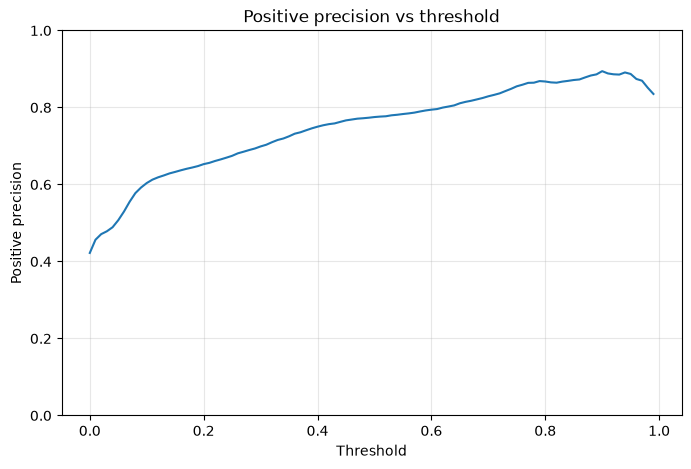

In [68]:
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision_pos)
plt.xlabel("Threshold")
plt.ylabel("Positive precision")
plt.title("Positive precision vs threshold")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.show()

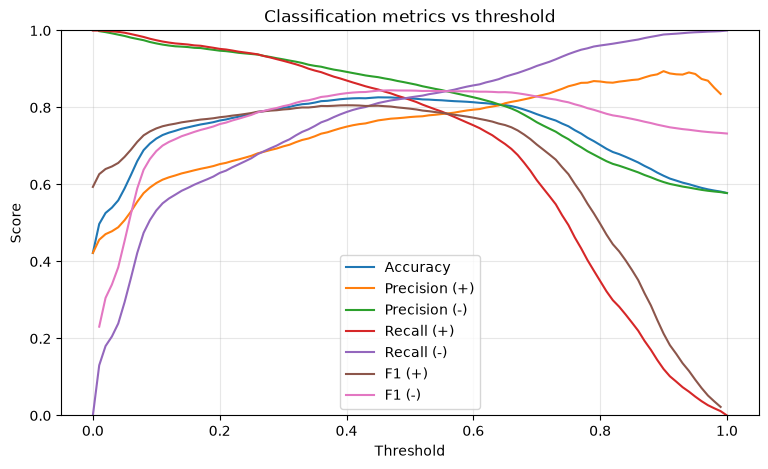

In [69]:
plt.figure(figsize=(9, 5))

metrics = [accuracy, precision_pos, precision_neg,
           recall_pos, recall_neg, f1_pos, f1_neg]

labels = ['Accuracy', 'Precision (+)', 'Precision (-)',
          'Recall (+)', 'Recall (-)', 'F1 (+)', 'F1 (-)']

for metric, label in zip(metrics, labels):
    plt.plot(thresholds, metric, label=label)

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Classification metrics vs threshold")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

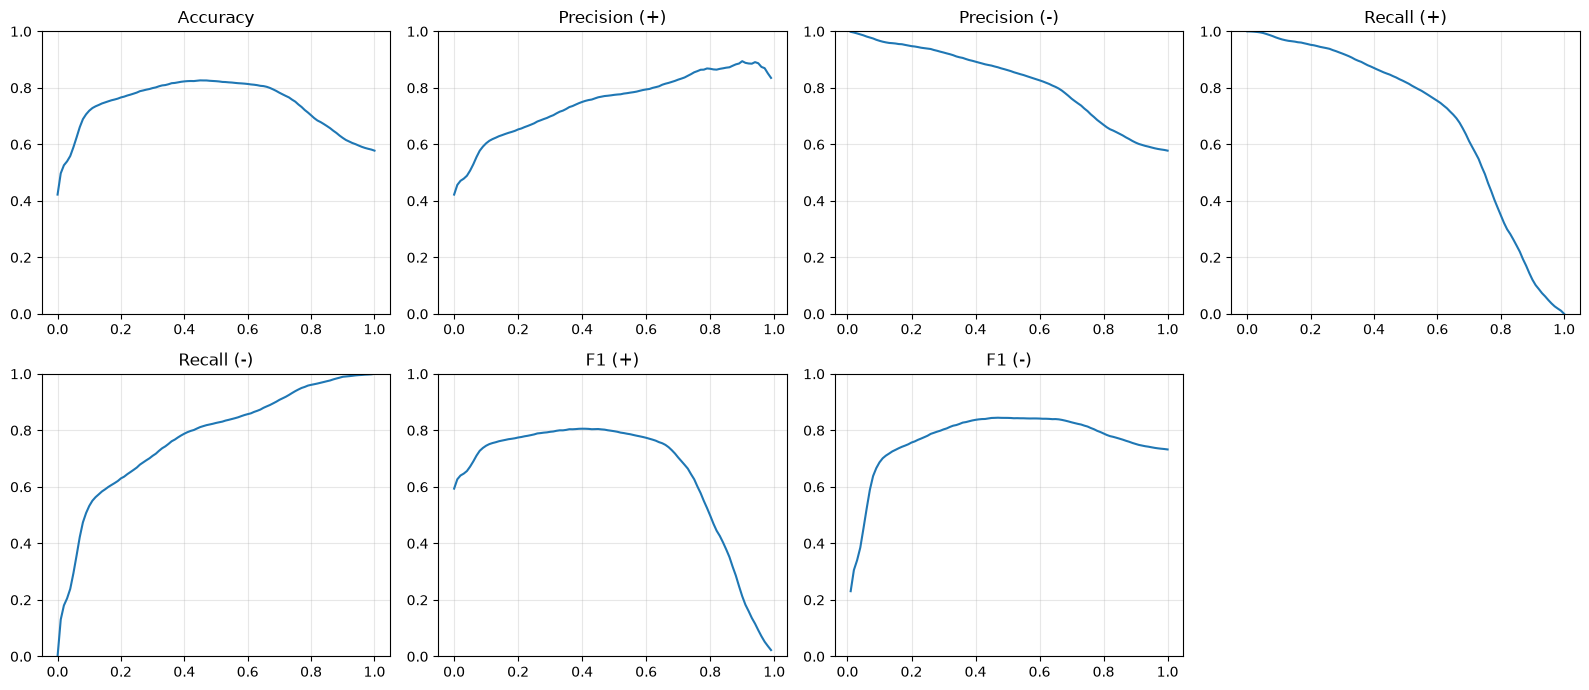

In [72]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for ax, metric, label in zip(axes.flat, metrics, labels):
    ax.plot(thresholds, metric)
    ax.set_title(label)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)

axes[1, 3].axis('off')  # Empty 8th subplot

plt.tight_layout()
plt.show()

### D) Plot in a bar chart the coefficients of the logistic regression sorted by their contribution to the prediction.


## Question 1: Which of the following metrics is most suitable when you are dealing with unbalanced classes?

- a) F1 Score
- b) Recall
- c) Precision
- d) Accuracy

## Question 2: You are working on a binary classification problem. You trained a model on a training dataset and got the following confusion matrix on the test dataset. What is true about the evaluation metrics (rounded to the second decimal point):

|            | Pred = NO|Pred=YES|
|------------|----------|--------|
| Actual NO  |    50    |   10   |
| Actual YES |    5     |   100  |

- a) Accuracy is 0.95
- b) Accuracy is 0.85
- c) False positive rate is 0.95
- d) True positive rate is 0.95